# Linear static analysis

This example computes the displacement, strain and stress fields of a laminated plate compressed by a load distributed along one edge, for the five models of `panels` that the example compares.

A `Shell` object describes a plate or a cylindrical shell through its attributes: the geometry, the laminate, the number of terms `m` and `n` of the approximation functions and the model, by default `'plate_clpt_donnell'` for plates and `'cylshell_clpt_sanders'` for cylindrical shells; see `panels.models` for the other models. The displacements are Ritz series, each term a product of a function of $x$ and a function of $y$. These functions are the Legendre-based hierarchical functions of Bardell (1991), in the form of Castro and Donadon (2017), see [Bardell's functions](../bardell.rst). Minimizing the total potential energy with respect to the Ritz constants $\boldsymbol{c}$ gives the linear system

$$
\boldsymbol{K}_C \boldsymbol{c} = \boldsymbol{F}_{ext},
$$

where $\boldsymbol{K}_C$ is the constitutive stiffness matrix, `Shell.calc_kC`, and $\boldsymbol{F}_{ext}$ the external force vector, `Shell.calc_fext`. The system is solved with `structsolve.static`, and the fields are recovered from $\boldsymbol{c}$ with `Shell.uvw`, `Shell.strain` and `Shell.stress`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import static
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Plate, laminate and boundary conditions

The plate is $a = 2$ m long along $x$ and $b = 1$ m wide along $y$. The laminate $[0/-45/+45/90/+45/-45/0/0]$ of carbon/epoxy plies of 0.125 mm is unsymmetric, so the coupling matrix $\boldsymbol{B}$ is not zero and an in-plane load also bends the plate. The material is given by `laminaprop` $= (E_{11}, E_{22}, \nu_{12}, G_{12}, G_{13}, G_{23})$.

The boundary conditions are the flags `x1u`, `x1ur`, `x2u`, ..., `y2wr`: `0` constrains and `1` releases the translation (e.g. `x1u`) or the rotation (e.g. `x1ur`) of each displacement component at the edges $x = 0$ (`x1`), $x = a$ (`x2`), $y = 0$ (`y1`) and $y = b$ (`y2`). The default is a simple support, with all translations constrained and all rotations free. Here $u$ is released at $x = 0$ and along the edges $y = 0, b$, and $v$ is constrained at all edges. The models based on shear deformation theories have the rotations as independent fields, with the analogous flags `x1phix`, `x1phixr`, ..., `y2phiyr`.

The load is a distributed force $N_{xx} = P/b$ along $x = 0$, `Shell.add_distr_load_fixed_x`, pointing along $+x$. Since $u = 0$ at $x = a$, it compresses the plate. With `cte=False` the load enters $\boldsymbol{F}_{ext}$; with `cte=True` it would be a constant load in the non-linear analyses.

In [2]:
def build_plate(model, m=7, n=6, P=1000.):
    s = Shell()
    s.model = model
    s.a = 2.
    s.b = 1.
    s.r = 1.e5  # used by the cylindrical shell models, nearly flat
    s.stack = [0, -45, +45, 90, +45, -45, 0, 0]
    s.plyt = 0.125e-3
    s.laminaprop = (142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9)
    s.m = m
    s.n = n
    s.nx = m
    s.ny = n
    s.x1u = 1
    s.y1u = 1
    s.y2u = 1
    s.x1v = s.x2v = s.y1v = s.y2v = 0
    s.add_distr_load_fixed_x(0, funcx=lambda y: P/s.b, funcy=None,
                             funcz=None, cte=False)
    return s


s = build_plate('plate_clpt_donnell')
print('number of Ritz constants:', s.get_size())

number of Ritz constants: 126


## Solving the linear system

`structsolve.static` returns the load increments and one vector of Ritz constants per increment; a linear analysis has one increment.

In [3]:
increments, cs = static(s.calc_kC(), s.calc_fext(), silent=True)
c = cs[0]
print('A11 = %.4e N/m, B11 = %.4e N, D11 = %.4e N m'
      % (s.ABD[0, 0], s.ABD[0, 3], s.ABD[3, 3]))
mesh, fields = s.uvw(c)
X, Y, w = mesh['Xs'], mesh['Ys'], fields['w'].copy()
u = fields['u'].copy()
_, fields = s.stress(c)
Nxx = fields['Nxx'].copy()
_, fields = s.strain(c)
eyy = fields['eyy'].copy()
print('max w = %.5e m, min Nxx = %.4f N/m, min eyy = %.5e'
      % (w.max(), Nxx.min(), eyy.min()))

A11 = 7.6940e+07 N/m, B11 = 4.1403e+03 N, D11 = 9.6558e+00 N m


max w = 1.39320e-04 m, min Nxx = -1017.4018 N/m, min eyy = -4.14515e-07


## Fields

The axial displacement $u$ is nearly linear in $x$, as in a bar. The deflection $w$ comes from the coupling $\boldsymbol{B}$ of the unsymmetric laminate. $N_{xx}$ is close to the applied $-P/b = -1000$ N/m, and differs from it near the edges, where $v = 0$ restrains the Poisson effect.

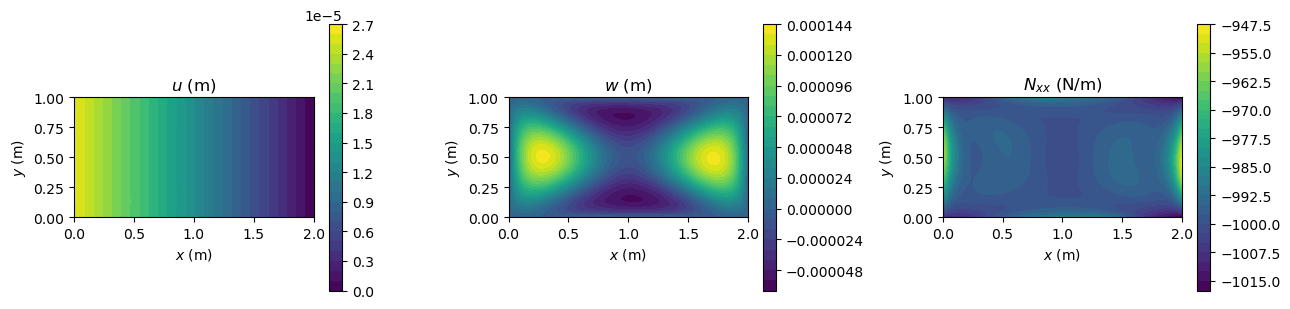

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, field, title in zip(axes, (u, w, Nxx),
                            ('$u$ (m)', '$w$ (m)', '$N_{xx}$ (N/m)')):
    cf = ax.contourf(X, Y, field, levels=30, cmap='viridis')
    fig.colorbar(cf, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
    ax.set_aspect('equal')
fig.tight_layout()
plt.show()

## The five models

The same plate is solved with the classical laminated plate theory (CLPT) for a plate and for cylindrical shells with Donnell's and Sanders' kinematics, the shell models with a large radius $r = 10^5$ m. It is also solved with the first-order (FSDT) and the third-order (TSDT) shear deformation theories for plates. The plate is thin, $a/h = 2000$: the three plate models agree within $10^{-4}$, and the two cylindrical shell models give a maximum deflection 3.5% larger and the same stress resultants within $3 \times 10^{-4}$.

The reference values are regression values of the panels unit test `tests/tests_shell/test_field_outputs.py`: no literature value exists for this laminate and these boundary conditions. The test checks them within 5% for $w$ and 0.1% for $N_{xx}$ and $\varepsilon_{yy}$.

In [5]:
REF = {'max w (m)': 0.00014, 'min Nxx (N/m)': -1017.4018,
       'min eyy': -4.1451e-07}
SOURCE = 'regression value, `test_field_outputs.py`'
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders', 'plate_fsdt_donnell',
              'plate_tsdt_donnell']:
    s = build_plate(model)
    increments, cs = static(s.calc_kC(), s.calc_fext(), silent=True)
    _, f = s.uvw(cs[0])
    wmax = f['w'].max()
    _, f = s.stress(cs[0])
    Nmin = f['Nxx'].min()
    _, f = s.strain(cs[0])
    emin = f['eyy'].min()
    print('%-22s max w %.5e m, min Nxx %.4f N/m, min eyy %.5e'
          % (model, wmax, Nmin, emin))
    for (name, ref), val in zip(REF.items(), (wmax, Nmin, emin)):
        rows.append(('`%s`: %s' % (model, name), val, ref, SOURCE))
results_table(rows)

plate_clpt_donnell     max w 1.39320e-04 m, min Nxx -1017.4018 N/m, min eyy -4.14515e-07


cylshell_clpt_donnell  max w 1.44208e-04 m, min Nxx -1017.1063 N/m, min eyy -4.15667e-07


cylshell_clpt_sanders  max w 1.44208e-04 m, min Nxx -1017.1063 N/m, min eyy -4.15667e-07


plate_fsdt_donnell     max w 1.39317e-04 m, min Nxx -1017.4017 N/m, min eyy -4.14583e-07


plate_tsdt_donnell     max w 1.39316e-04 m, min Nxx -1017.4023 N/m, min eyy -4.14579e-07


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`: max w (m) | 0.00013932 | 0.00014 | -4.86e-03 | regression value, `test_field_outputs.py` |
| `plate_clpt_donnell`: min Nxx (N/m) | -1017.4 | -1017.4 | -3.92e-08 | regression value, `test_field_outputs.py` |
| `plate_clpt_donnell`: min eyy | -4.14515e-07 | -4.1451e-07 | -1.11e-05 | regression value, `test_field_outputs.py` |
| `cylshell_clpt_donnell`: max w (m) | 0.000144208 | 0.00014 | +3.01e-02 | regression value, `test_field_outputs.py` |
| `cylshell_clpt_donnell`: min Nxx (N/m) | -1017.11 | -1017.4 | +2.90e-04 | regression value, `test_field_outputs.py` |
| `cylshell_clpt_donnell`: min eyy | -4.15667e-07 | -4.1451e-07 | -2.79e-03 | regression value, `test_field_outputs.py` |
| `cylshell_clpt_sanders`: max w (m) | 0.000144208 | 0.00014 | +3.01e-02 | regression value, `test_field_outputs.py` |
| `cylshell_clpt_sanders`: min Nxx (N/m) | -1017.11 | -1017.4 | +2.90e-04 | regression value, `test_field_outputs.py` |
| `cylshell_clpt_sanders`: min eyy | -4.15667e-07 | -4.1451e-07 | -2.79e-03 | regression value, `test_field_outputs.py` |
| `plate_fsdt_donnell`: max w (m) | 0.000139317 | 0.00014 | -4.88e-03 | regression value, `test_field_outputs.py` |
| `plate_fsdt_donnell`: min Nxx (N/m) | -1017.4 | -1017.4 | +8.84e-08 | regression value, `test_field_outputs.py` |
| `plate_fsdt_donnell`: min eyy | -4.14583e-07 | -4.1451e-07 | -1.77e-04 | regression value, `test_field_outputs.py` |
| `plate_tsdt_donnell`: max w (m) | 0.000139316 | 0.00014 | -4.89e-03 | regression value, `test_field_outputs.py` |
| `plate_tsdt_donnell`: min Nxx (N/m) | -1017.4 | -1017.4 | -5.31e-07 | regression value, `test_field_outputs.py` |
| `plate_tsdt_donnell`: min eyy | -4.14579e-07 | -4.1451e-07 | -1.68e-04 | regression value, `test_field_outputs.py` |

## References

1. N. S. Bardell, "Free vibration analysis of a flat plate using the hierarchical finite element method". Journal of Sound and Vibration, 151(2):263-289, 1991. https://doi.org/10.1016/0022-460X(91)90855-E.
2. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.